# Supplementary Figure S6c. MSigDB Hallmark trans-MaxPIP annotations

Heritability enrichment, marginal τ* and joint τ* of trans-MaxPIP annotations built from the 50 MSigDB Hallmark gene sets with four program representations (TransMap = WPC, TransPCO*, AUCell, Eigengene = PC1); joint τ* comes from one model with the four annotations (`Joint_MSigDB_Hallmark_Trans_Methods`). Source: `Functional_Program_comparison/sLDSC_MSigDB_Hallmark.ipynb` cells 53-63 and `Manu_Figures/Figure2_Function_Program.ipynb` cell 2 (input `sLDSC_MSigDB_Hallmark_Joint_Trans_Methods.rds`; the recomputed values match it to machine precision).

Error bars are estimate ± 1.96 × SE (95% CI), as drawn by the source helpers `plotEnrichForest` / `plotTauForest` (sldsc_utils.R). Significance symbols follow the source `pToSymbol`: **** P < 1e-4, *** P < 1e-3, ** P < 0.01, * P < 0.05, . P < 0.1, shown only when the estimate is > 0 (also for enrichment, whose null is 1). P-values are nominal and two-sided; no multiple-testing correction is applied (the rds also carries `fdr_bh`, a Benjamini–Hochberg adjustment across all tests of the same metric in the panel, for reference only). Dashed lines: 1 for enrichment, 0 for τ*. All S-LDSC values are random-effects meta-analyses across traits (57 all, 18 brain, 22 blood; per-trait models conditional on the 53 baseline-LD annotations), recomputed here from the per-trait S-LDSC outputs with a re-implementation of the author's meta-analysis code.

Discrepancy with the published panel: for brain-related traits the joint τ* of TransMap is 0.054 (SE 0.0286, P = 0.058, symbol ".") in every stored result (this recomputation, `sLDSC_MSigDB_Hallmark_Joint_Trans_Methods.rds`, `sLDSC_MSigDB_Hallmark_Joint.rds` and the plotted copy `Figure_SLDSC_Xa_MsigDB_Trans_Methods.rds`), but the manuscript figure shows a narrower interval that excludes 0 (implied SE ≈ 0.021) and a "*". No code or result file reproducing the published version was found.

Input: `data/Figure_S6c_hallmark_sldsc.rds`.

In [1]:
library(ggplot2)
library(patchwork)
d <- readRDS("data/Figure_S6c_hallmark_sldsc.rds")
d

metric,trait_set,trait,method,annotation_raw,est,se,pvalue,fdr_bh,n_traits
<fct>,<chr>,<fct>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Enrichment,all_traits,All traits (57),TransMap,MSigDB_Hallmark_wPC,2.4844594103,0.23011649,1.270218e-07,1.524261e-06,57
Enrichment,blood_traits,Blood-related traits (22),TransMap,MSigDB_Hallmark_wPC,2.7045423511,0.50103695,1.392643e-02,3.342344e-02,22
Enrichment,brain_traits,Brain-related traits (18),TransMap,MSigDB_Hallmark_wPC,2.1368442474,0.38702472,7.411873e-04,2.223562e-03,18
Enrichment,all_traits,All traits (57),TransPCO*,MSigDB_Hallmark_aPC,2.5431726931,0.45997626,2.179308e-04,1.307585e-03,57
Enrichment,blood_traits,Blood-related traits (22),TransPCO*,MSigDB_Hallmark_aPC,1.2319473441,0.71391360,4.832893e-01,5.799472e-01,22
Enrichment,brain_traits,Brain-related traits (18),TransPCO*,MSigDB_Hallmark_aPC,3.7790296720,1.05994324,3.579787e-04,1.431915e-03,18
Enrichment,all_traits,All traits (57),AUCell,MSigDB_Hallmark_AUCell,0.4361995254,0.92656026,5.560060e-01,6.065520e-01,57
Enrichment,blood_traits,Blood-related traits (22),AUCell,MSigDB_Hallmark_AUCell,0.9467288705,2.16130383,6.779156e-01,6.779156e-01,22
Enrichment,brain_traits,Brain-related traits (18),AUCell,MSigDB_Hallmark_AUCell,1.6144856186,1.54757325,2.711725e-01,3.615634e-01,18


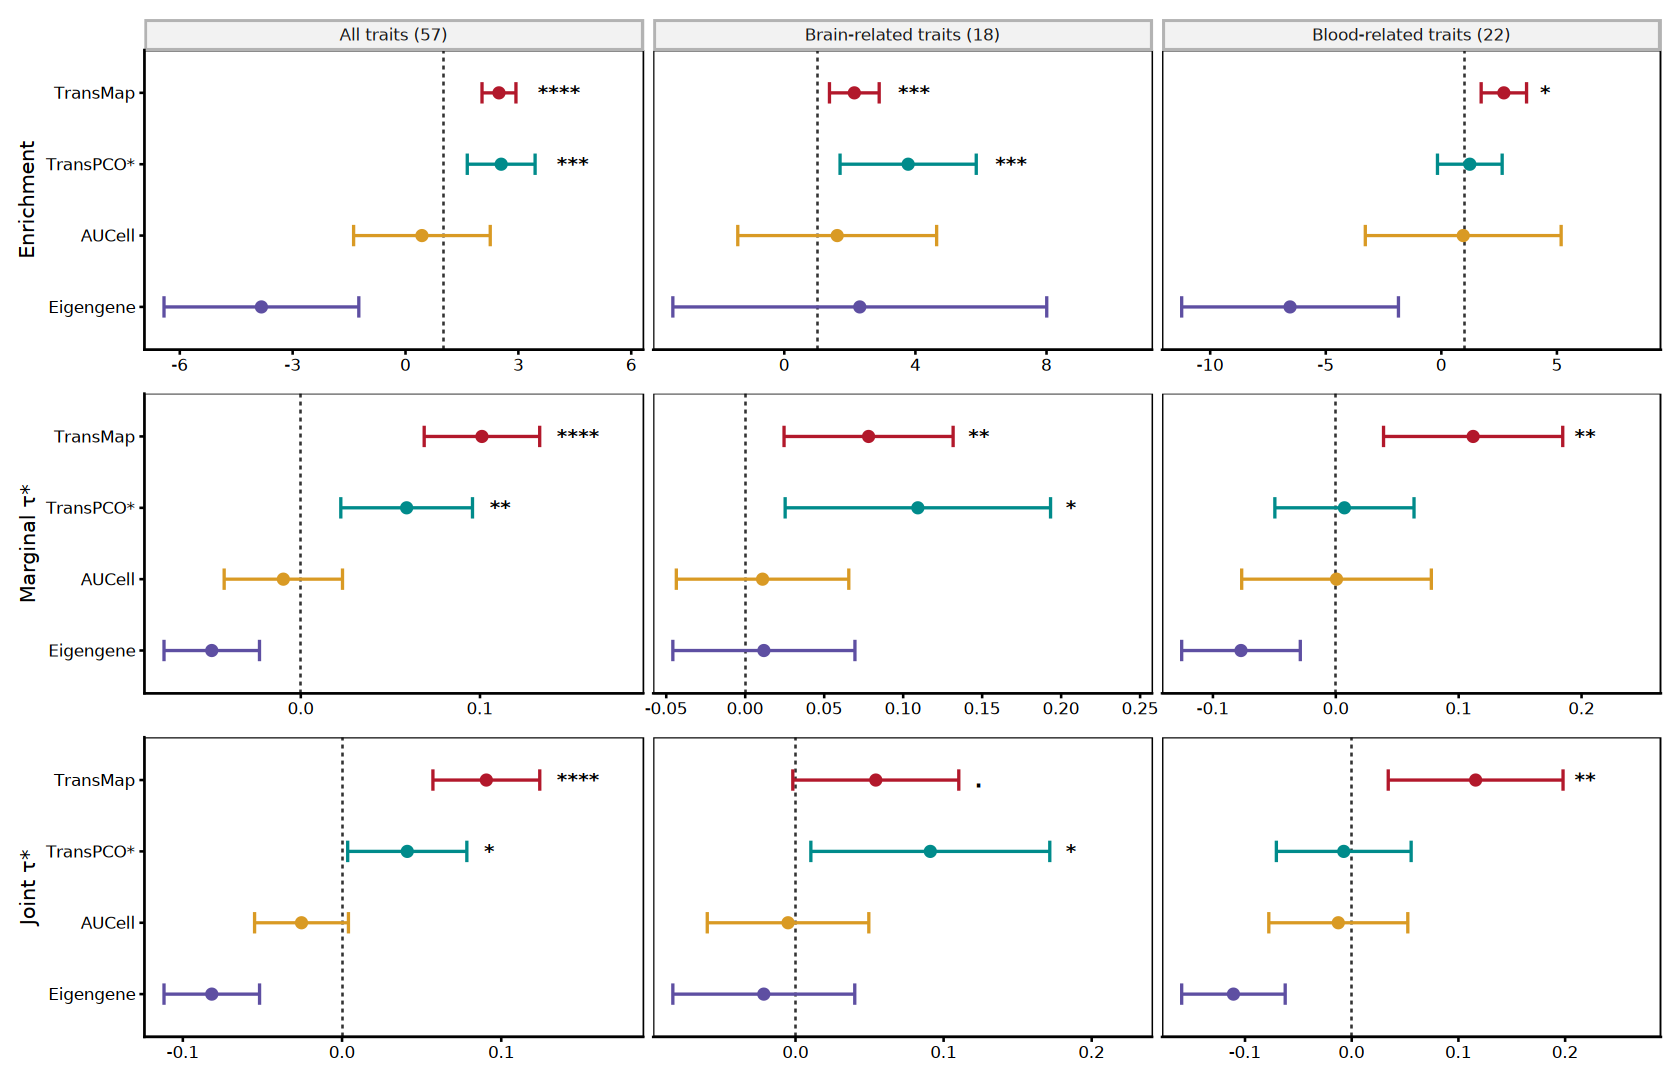

In [2]:
p_sym <- function(p, est) {
  s <- c("****", "***", "**", "*", ".", "")[findInterval(p, c(0, 1e-4, 1e-3, 0.01, 0.05, 0.1, Inf), rightmost.closed = TRUE)]
  ifelse(est > 0, s, "")
}
forest <- function(d, cols, ylab, vline, show_strip = TRUE) {
  d$lo <- d$est - 1.96 * d$se; d$hi <- d$est + 1.96 * d$se
  d$sym <- p_sym(d$pvalue, d$est)
  pad <- 0.03 * diff(range(c(d$lo, d$hi, vline)))
  p <- ggplot(d, aes(y = annotation, colour = annotation)) +
    geom_vline(xintercept = vline, linetype = "dashed", colour = "grey20") +
    geom_errorbar(aes(xmin = lo, xmax = hi), width = 0.3, orientation = "y", linewidth = 0.7) +
    geom_point(aes(x = est), size = 2.6) +
    geom_text(aes(x = hi + pad, label = sym), colour = "black", hjust = 0, size = 4.2, fontface = "bold") +
    facet_grid(. ~ trait, scales = "free_x") +
    scale_colour_manual(values = cols, guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(expand = expansion(mult = c(0.05, 0.22))) +
    labs(x = NULL, y = ylab) +
    theme_classic(base_size = 12) +
    theme(strip.background = element_rect(fill = "grey95", colour = "grey70"),
          panel.border = element_rect(colour = "black", fill = NA, linewidth = 0.4))
  if (!show_strip) p <- p + theme(strip.text = element_blank(), strip.background = element_blank())
  p
}

cols <- c("TransMap" = "#B2182B", "TransPCO*" = "#008B8B", "AUCell" = "#D99A24", "Eigengene" = "#5E4FA2")
GROUP <- "method"

d$annotation <- d[[GROUP]]
rows <- list(
  forest(subset(d, metric == "Enrichment"), cols, "Enrichment", 1, TRUE),
  forest(subset(d, metric == "Marginal tau*"), cols, expression("Marginal " * tau * "*"), 0, FALSE),
  forest(subset(d, metric == "Joint tau*"), cols, expression("Joint " * tau * "*"), 0, FALSE))
options(repr.plot.width = 14, repr.plot.height = 9)
wrap_plots(rows, ncol = 1)